# Анализ и прогнозирование временных рядов методами искусственного интеллекта

## **Практическая работа 6. Поиск эволюционирующих шаблонов с помощью матричного профиля ряда.**

In [1]:
%load_ext autoreload
%autoreload 2

## **Часть 1.** Поиск цепочек временного ряда.

Импорт библиотек и модулей

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import stumpy
from sklearn.metrics import mean_squared_error
from pathlib import Path
from IPython.display import display

assert Path('datasets').is_dir(), 'Откройте ноутбук из каталога практики 6.'
np.random.seed(42)

/Users/mikhail/Developer/2026-autumn/AFTSAIM-2026/.venv/lib/python3.12/site-packages/stumpy/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


В первом задании вам предстоит выполнить поиск эволюционирующих шаблонов временного ряда. Выполните считывание набора данных [Rotation Matrix](datasets/Rotation%20Matrix.txt), найдите в нем самую длинную цепочку и выведите индексы начала звеньев этой цепочки.

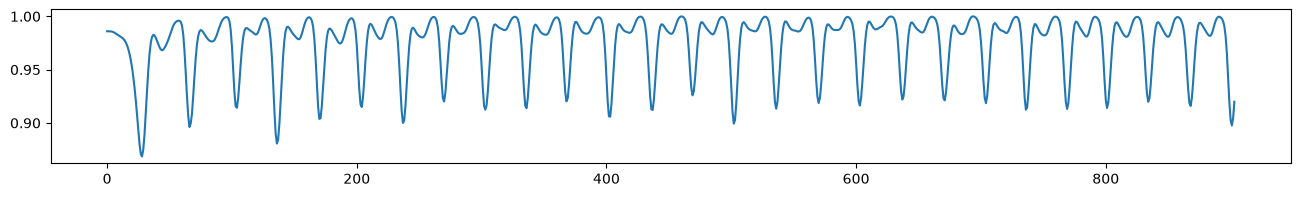

In [3]:
fig, ax = plt.subplots(figsize=(16, 2))
ts = np.loadtxt('datasets/Rotation Matrix.txt')
assert ts.shape == (904,) and np.isfinite(ts).all()
ax.plot(ts)

In [4]:
# INSERT YOUR CODE
m = 25
matrix_profile = stumpy.stump(ts, m=m)
left_indices = np.asarray(matrix_profile[:, 2], dtype=np.int64)
right_indices = np.asarray(matrix_profile[:, 3], dtype=np.int64)
all_chain_set, chain_indices = stumpy.allc(left_indices, right_indices)

In [5]:
print(f"Индексы начала звеньев самой длинной цепочки: {chain_indices.tolist()}")
print(f'Число звеньев: {len(chain_indices)}; длина звена: {m}')
telegram_chain = np.array([199, 331, 398, 432, 863])
print('Совпадает с Telegram:', np.array_equal(chain_indices, telegram_chain))

Индексы начала звеньев самой длинной цепочки: [199, 331, 398, 432, 863]
Число звеньев: 5; длина звена: 25
Совпадает с Telegram: True


❓ Проанализируйте и изложите содержательный смысл полученных результатов.

Найдено **503 цепочки**, максимальная длина — **5 звеньев** по **25 отсчётов**. Основная самая длинная цепочка начинается в позициях **[199, 331, 398, 432, 863]**, что совпадает с результатом Telegram.

Для каждой соседней пары звеньев проверена взаимность связей: правый ближайший сосед предыдущего окна — следующее окно, а его левый ближайший сосед — предыдущее. Поэтому цепочка задаёт последовательность локально связанных похожих форм, а не просто набор минимумов профиля. Самая длинная цепочка не обязательно единственная: в визуализации показаны две цепочки одинаковой максимальной длины.

In [6]:
# Параметр: топ N самых длинных цепочек
TOP_N = 2

# Сортируем цепочки по длине (количеству звеньев) и берем топ N
chain_lengths = [(i, len(chain)) for i, chain in enumerate(all_chain_set)]
chain_lengths.sort(key=lambda x: (-x[1], tuple(all_chain_set[x[0]])))
top_chain_indices = [idx for idx, _ in chain_lengths[:TOP_N]]
top_chains = [all_chain_set[idx] for idx in top_chain_indices]

print(f"Всего найдено цепочек: {len(all_chain_set)}")
print(f"Отображаем топ-{TOP_N} самых длинных цепочек:\n")
for rank, (orig_idx, length) in enumerate(chain_lengths[:TOP_N], 1):
    print(f"{rank}. {all_chain_set[orig_idx].tolist()}: {length} звеньев")

Всего найдено цепочек: 503
Отображаем топ-2 самых длинных цепочек:

1. [199, 331, 398, 432, 863]: 5 звеньев
2. [237, 303, 570, 637, 736]: 5 звеньев


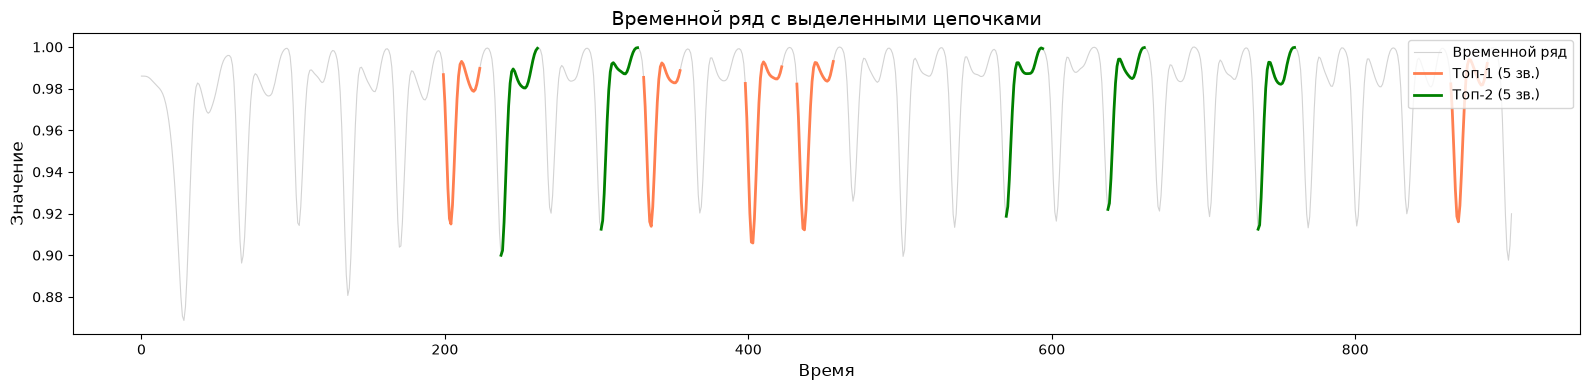

In [7]:
fig, ax = plt.subplots(figsize=(16, 4))

# Отображение временного ряда
ax.plot(ts, color='lightgray', linewidth=0.8, label='Временной ряд')

# Генерация цветов для каждой цепочки
colors = ['coral', 'green', 'orange', 'brown', 'yellow', 'magenta']

# Отображение каждой цепочки своим цветом
for chain_idx, orig_idx in enumerate(top_chain_indices):
    chain = all_chain_set[orig_idx]
    for segment_idx in chain:
        start = segment_idx
        end = segment_idx + m
        ax.plot(range(start, end), ts[start:end],
                color=colors[chain_idx], linewidth=2,
                label=f'Топ-{chain_idx + 1} ({len(chain)} зв.)' if segment_idx == chain[0] else '')

ax.set_xlabel('Время', fontsize=12)
ax.set_ylabel('Значение', fontsize=12)
ax.set_title('Временной ряд с выделенными цепочками', fontsize=14)

# Убираем дубликаты в легенде
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), loc='upper right')

plt.tight_layout()
plt.show()


## **Часть 2. Визуализация цепочек**

Выполните визуализацию найденных в прошлом задании цепочек: постройте график временного ряда, на котором выделены звенья цепочек. Также постройте график, на котором изображены только сами звенья.

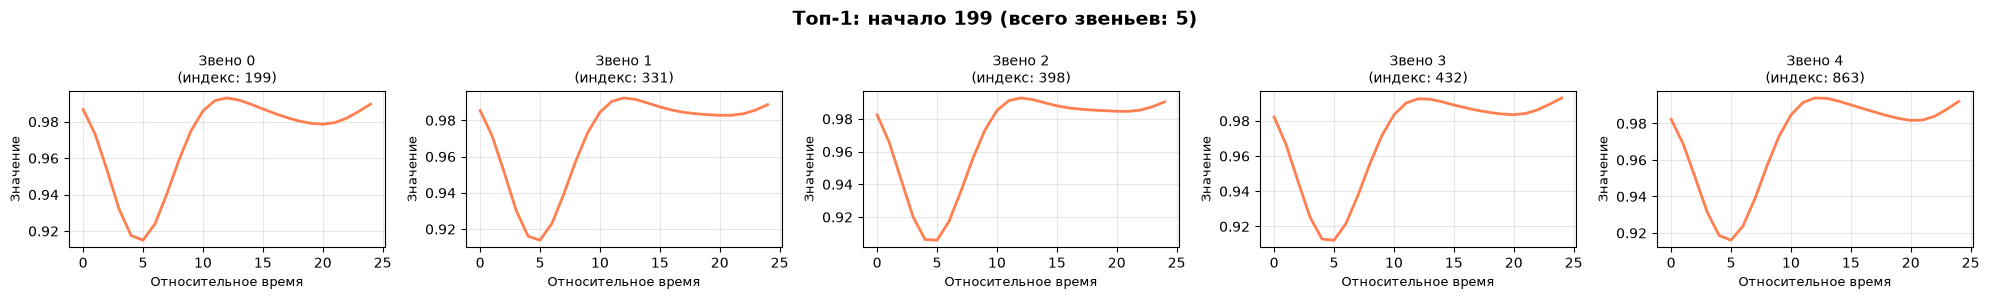

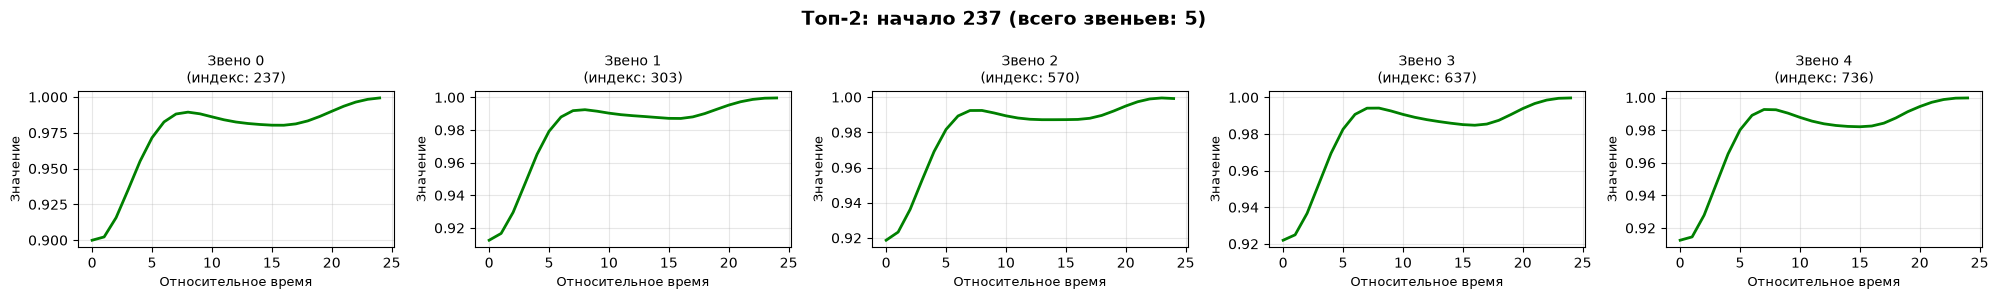

In [8]:
# INSERT YOUR CODE
for rank, (chain_idx, orig_idx) in enumerate(zip(range(len(top_chains)), top_chain_indices), 1):
    chain = all_chain_set[orig_idx]
    n_segments = len(chain)

    # Создаем сетку подграфиков для текущей цепочки
    fig, axes = plt.subplots(1, n_segments, figsize=(4*n_segments, 3))

    # Если только одно звено, axes не будет массивом
    if n_segments == 1:
        axes = [axes]

    fig.suptitle(f'Топ-{rank}: начало {chain[0]} (всего звеньев: {n_segments})',
                 fontsize=14, fontweight='bold')

    # Отображаем каждое звено
    for i, segment_idx in enumerate(chain):
        start = segment_idx
        end = segment_idx + m
        segment = ts[start:end]

        axes[i].plot(segment, color=colors[chain_idx], linewidth=2)
        axes[i].set_title(f'Звено {i}\n(индекс: {segment_idx})', fontsize=10)
        axes[i].set_xlabel('Относительное время', fontsize=9)
        axes[i].set_ylabel('Значение', fontsize=9)
        axes[i].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

❓ Проанализируйте и изложите содержательный смысл полученных результатов.

Показаны две цепочки по пять звеньев:

1. `[199, 331, 398, 432, 863]`.
2. `[237, 303, 570, 637, 736]`.

Цепочки упорядочены по убыванию количества звеньев, затем по индексам начала, чтобы равнозначные результаты отображались устойчиво. На исходном ряде каждая цепочка выделена своим цветом; отдельные панели показывают только звенья.

В основной цепочке сохраняется характерная форма провала с восстановлением, но меняются глубина и положение минимума и форма завершающего участка. Это согласуется с постепенным изменением шаблона; цепочка не требует точного совпадения исходных значений. Расстояния между началами звеньев неодинаковы, поэтому шаг цепочки не равен фиксированному временному интервалу.

## **Часть 3.** Предсказывание значений ряда на основе цепочек.

Предскажите значения последнего звена цепочки, вычислив разность между двумя предыдущими звеньями цепочки. Сравните полученное предсказание с истинным значением.

Входные звенья: 398, 432; целевое звено: 863
RMSE: 0.00191347


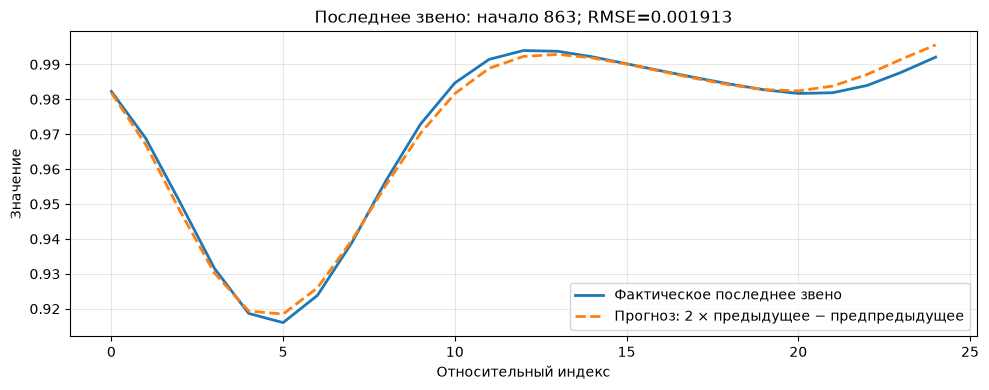

In [9]:
# INSERT YOUR CODE
def predict_link(before_previous, previous):
    """Продлить изменение формы двух предыдущих звеньев на один шаг цепочки."""
    return previous + (previous - before_previous)

assert len(chain_indices) >= 3
before_start, previous_start, target_start = map(int, chain_indices[-3:])
assert before_start + m <= target_start and previous_start + m <= target_start
before_previous = ts[before_start:before_start + m]
previous = ts[previous_start:previous_start + m]
prediction = predict_link(before_previous, previous)
actual = ts[target_start:target_start + m]
rmse = float(np.sqrt(mean_squared_error(actual, prediction)))
print(f'Входные звенья: {before_start}, {previous_start}; целевое звено: {target_start}')
print(f'RMSE: {rmse:.8f}')

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(actual, label='Фактическое последнее звено', linewidth=2)
ax.plot(prediction, '--', label='Прогноз: 2 × предыдущее − предпредыдущее', linewidth=2)
ax.set(xlabel='Относительный индекс', ylabel='Значение',
       title=f'Последнее звено: начало {target_start}; RMSE={rmse:.6f}')
ax.legend()
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

❓ Проанализируйте и изложите содержательный смысл полученных результатов.

По звеньям с началами **398** и **432** рассчитан прогноз звена с началом **863**:

`prediction = previous + (previous − before_previous)`.

Ошибка на **25** отсчётах составляет **RMSE = 0.00191347**. На графике прогноз сохраняет основную форму провала и восстановления. Небольшие расхождения видны около минимума, вершины восстановления и в конце звена. Прогноз вычисляется в исходном масштабе, без дополнительной нормализации.

Последнее звено не входит в численные входы экстраполяции: проверка с заменой его значений на NaN сохраняет прогноз. При этом сама цепочка найдена по полному ряду, включая последнее звено. Поэтому это **ретроспективная проверка**, а не доказательство качества прогнозирования неизвестного будущего. Формула продолжает изменение на один шаг цепочки без поправки на неодинаковые интервалы между звеньями.

In [10]:
import json
from pathlib import Path

assert len(chain_indices) == max(map(len, all_chain_set))
assert any(np.array_equal(chain_indices, chain) for chain in all_chain_set)
for chain in all_chain_set:
    assert len(chain) > 0
    assert np.all((chain >= 0) & (chain + m <= len(ts)))
    assert np.all(np.diff(chain) > 0)
    for first, second in zip(chain[:-1], chain[1:]):
        assert right_indices[first] == second
        assert left_indices[second] == first
expected_top = sorted(all_chain_set, key=lambda chain: (-len(chain), tuple(chain)))[:TOP_N]
assert all(np.array_equal(a, b) for a, b in zip(top_chains, expected_top))

# Контроль формулы на искусственной линейной эволюции формы.
a = np.arange(m, dtype=float)
b = a + 2
np.testing.assert_array_equal(predict_link(a, b), a + 4)

# Целевое звено не входит в численные входы экстраполяции.
without_target = ts.copy()
without_target[target_start:target_start + m] = np.nan
np.testing.assert_array_equal(
    predict_link(without_target[before_start:before_start + m],
                 without_target[previous_start:previous_start + m]), prediction,
)
assert len(prediction) == m and np.isfinite(prediction).all()
assert np.isfinite(rmse)
summary = {
    'n': len(ts), 'm': m, 'chains': len(all_chain_set),
    'longest_chain': chain_indices.tolist(),
    'top_chains': [chain.tolist() for chain in top_chains],
    'forecast_inputs': [before_start, previous_start], 'target_start': target_start,
    'rmse': rmse, 'actual_range': [float(actual.min()), float(actual.max())],
    'prediction_range': [float(prediction.min()), float(prediction.max())],
    'actual': actual.tolist(), 'prediction': prediction.tolist(),
}
Path('.cache/results.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2))
print('Проверки цепочек и прогноза пройдены')


Проверки цепочек и прогноза пройдены
